# Assignment 2: tuning curves and correlation heatmaps (V1 vs LM)

This notebook loads the files saved by `assignment2_download.ipynb` (no new downloads) and makes:

1. **Tuning curves**: average firing rate at each grating direction, with 95% confidence intervals, for every unit
2. **Correlation heatmaps**: an N × N matrix of pairwise correlations between units, plotted as an image

All figures are also saved as PNGs in `~/allen_neuropixels_data/assignment2/figures/` so you can drop them into slides.

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore", category=RuntimeWarning)

data_dir = os.path.expanduser("~/allen_neuropixels_data/assignment2")
fig_dir = os.path.join(data_dir, "figures")
os.makedirs(fig_dir, exist_ok=True)

V1, HOA = "VISp", "VISl"
AREA_NAMES = {V1: "V1", HOA: "LM"}

# Which grating speed to analyze.
# None = pool all 5 speeds together. Or set a number, e.g. TF = 2.0 for 2 Hz only.
TF = None

session_ids = sorted(int(os.path.basename(f).split("_")[0])
                     for f in glob.glob(os.path.join(data_dir, "*_units.pkl")))
session_ids

[750332458, 757216464]

## Load the data and count spikes per trial

For every trial and every unit we count spikes during the 2-second grating,
then divide by the trial's duration to get a **firing rate (spikes/s)**.
The result is a table with one row per trial and one column per unit.

In [2]:
def load_session(sid):
    stim = pd.read_pickle(os.path.join(data_dir, f"{sid}_stimulus.pkl")).copy()
    units = pd.read_pickle(os.path.join(data_dir, f"{sid}_units.pkl"))
    spikes = pd.read_pickle(os.path.join(data_dir, f"{sid}_spikes.pkl"))

    stim["orientation"] = stim["orientation"].astype(float)
    stim["temporal_frequency"] = stim["temporal_frequency"].astype(float)
    if TF is not None:
        stim = stim[stim["temporal_frequency"] == TF]

    counts = (spikes.groupby(["stimulus_presentation_id", "unit_id"]).size()
                    .unstack(fill_value=0)
                    .reindex(index=stim.index, columns=units.index, fill_value=0))
    rates = counts.div(stim["duration"], axis=0)
    return stim, units, counts, rates

data = {sid: load_session(sid) for sid in session_ids}

for sid, (stim, units, counts, rates) in data.items():
    a = units["ecephys_structure_acronym"]
    print(f"session {sid}: {len(stim)} trials | {(a == V1).sum()} V1 units | {(a == HOA).sum()} LM units")

session 750332458: 600 trials | 63 V1 units | 38 LM units
session 757216464: 600 trials | 85 V1 units | 53 LM units


## Analysis 1: tuning curves with 95% confidence intervals

For one unit: group its trials by direction, average the firing rate in each group,
and compute a 95% confidence interval for each average
(t-distribution × standard error, which suits small samples like 15 trials).

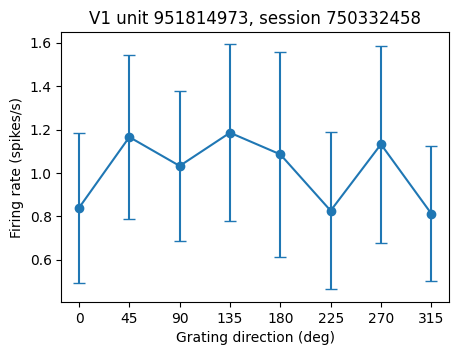

In [3]:
def tuning_curve(unit_rates, stim):
    g = unit_rates.groupby(stim["orientation"])
    mean = g.mean()
    n = g.count()
    sem = g.std(ddof=1) / np.sqrt(n)
    ci = stats.t.ppf(0.975, n - 1) * sem
    return mean, ci

# Close-up of a single unit (change the [0] to look at others)
sid = session_ids[0]
stim, units, counts, rates = data[sid]
uid = units.index[units["ecephys_structure_acronym"] == V1][0]
mean, ci = tuning_curve(rates[uid], stim)

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.errorbar(mean.index, mean.values, yerr=ci.values, fmt="o-", capsize=4)
ax.set(xlabel="Grating direction (deg)", ylabel="Firing rate (spikes/s)",
       title=f"V1 unit {uid}, session {sid}", xticks=mean.index)
plt.show()

### Tuning curves for every unit
One grid per area per session. Each small panel is one unit:
x = direction (deg), y = firing rate (spikes/s), error bars = 95% CI.

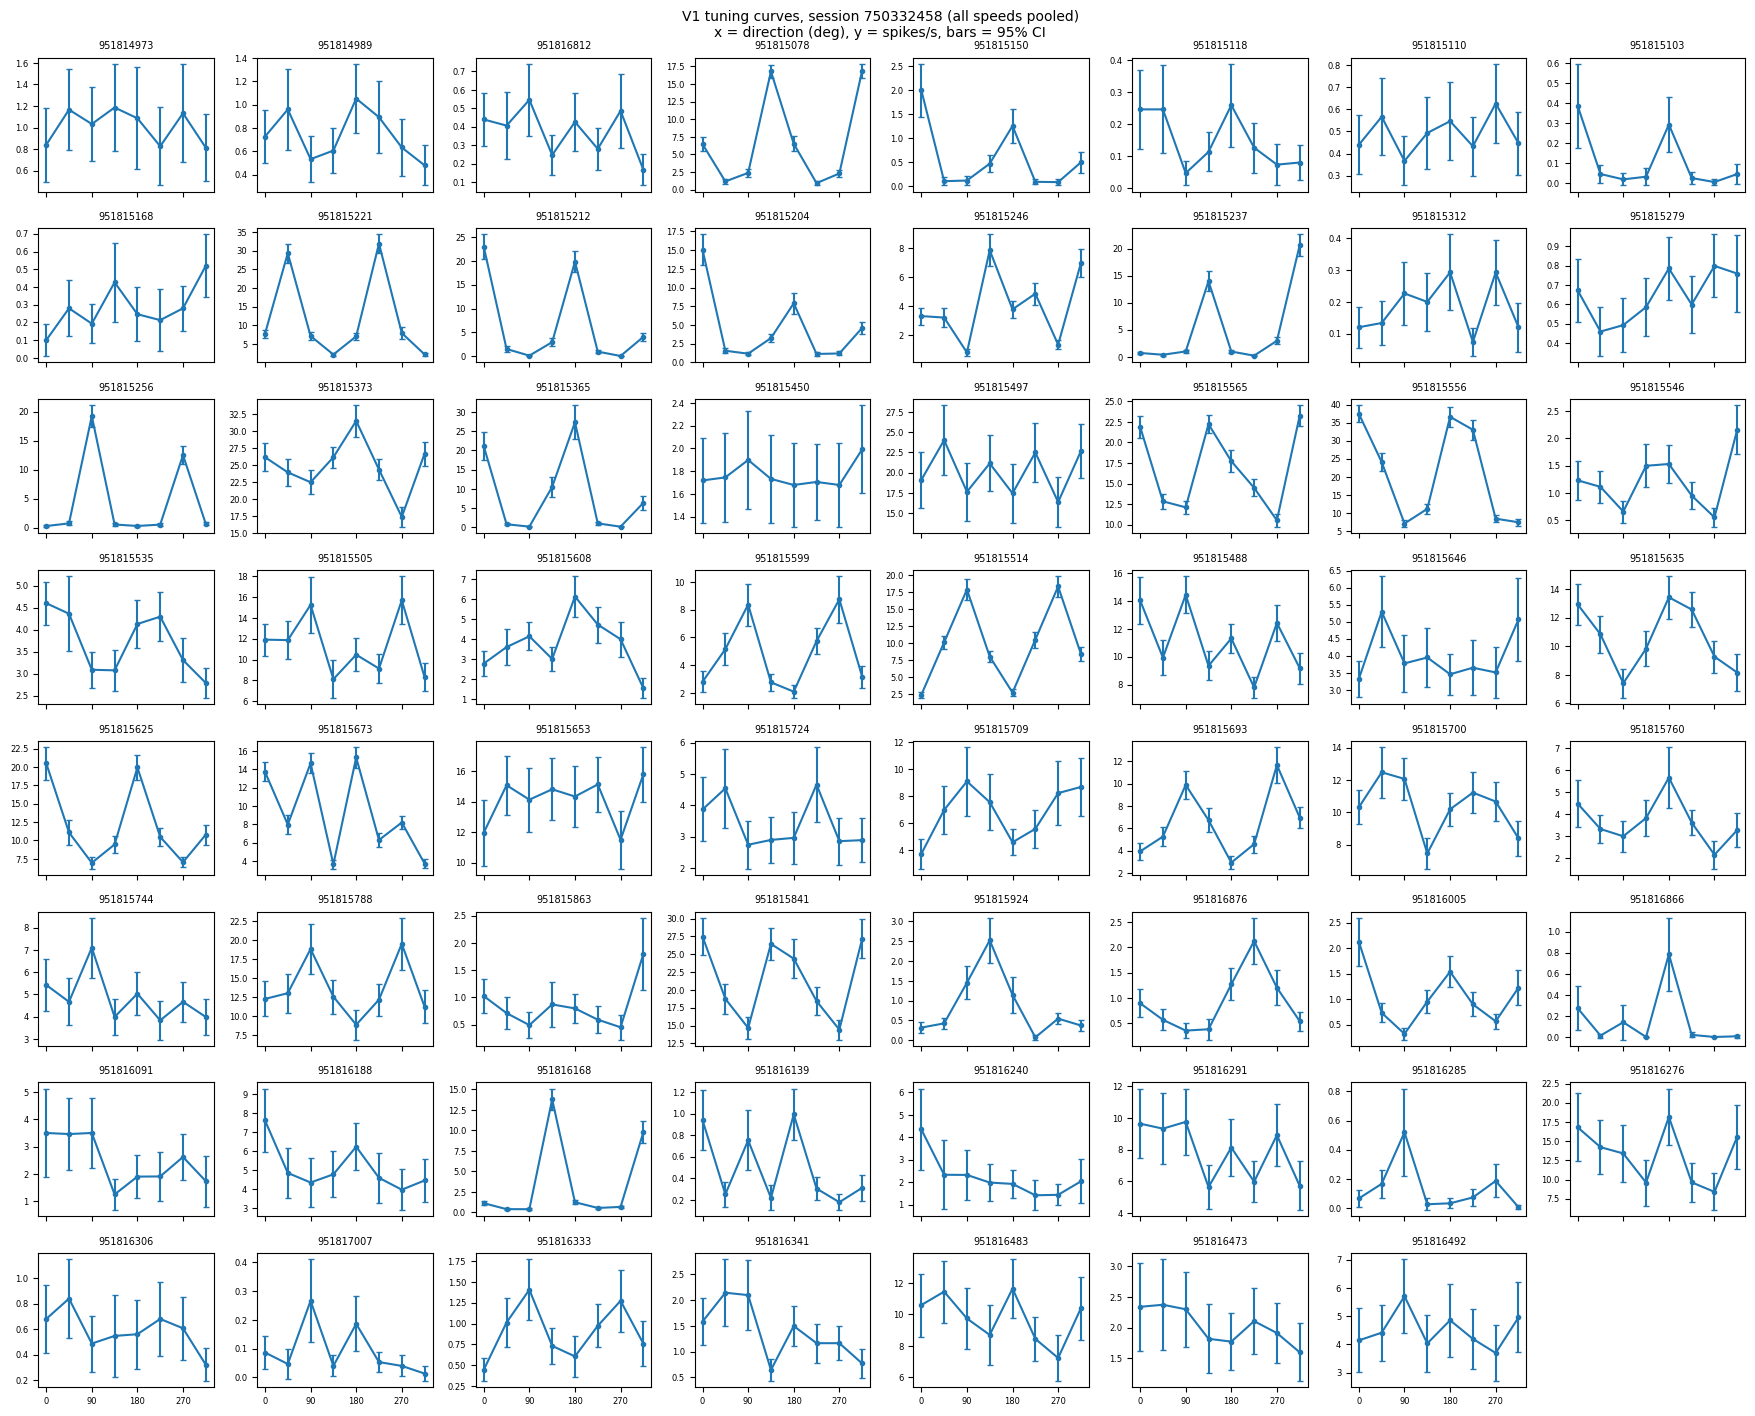

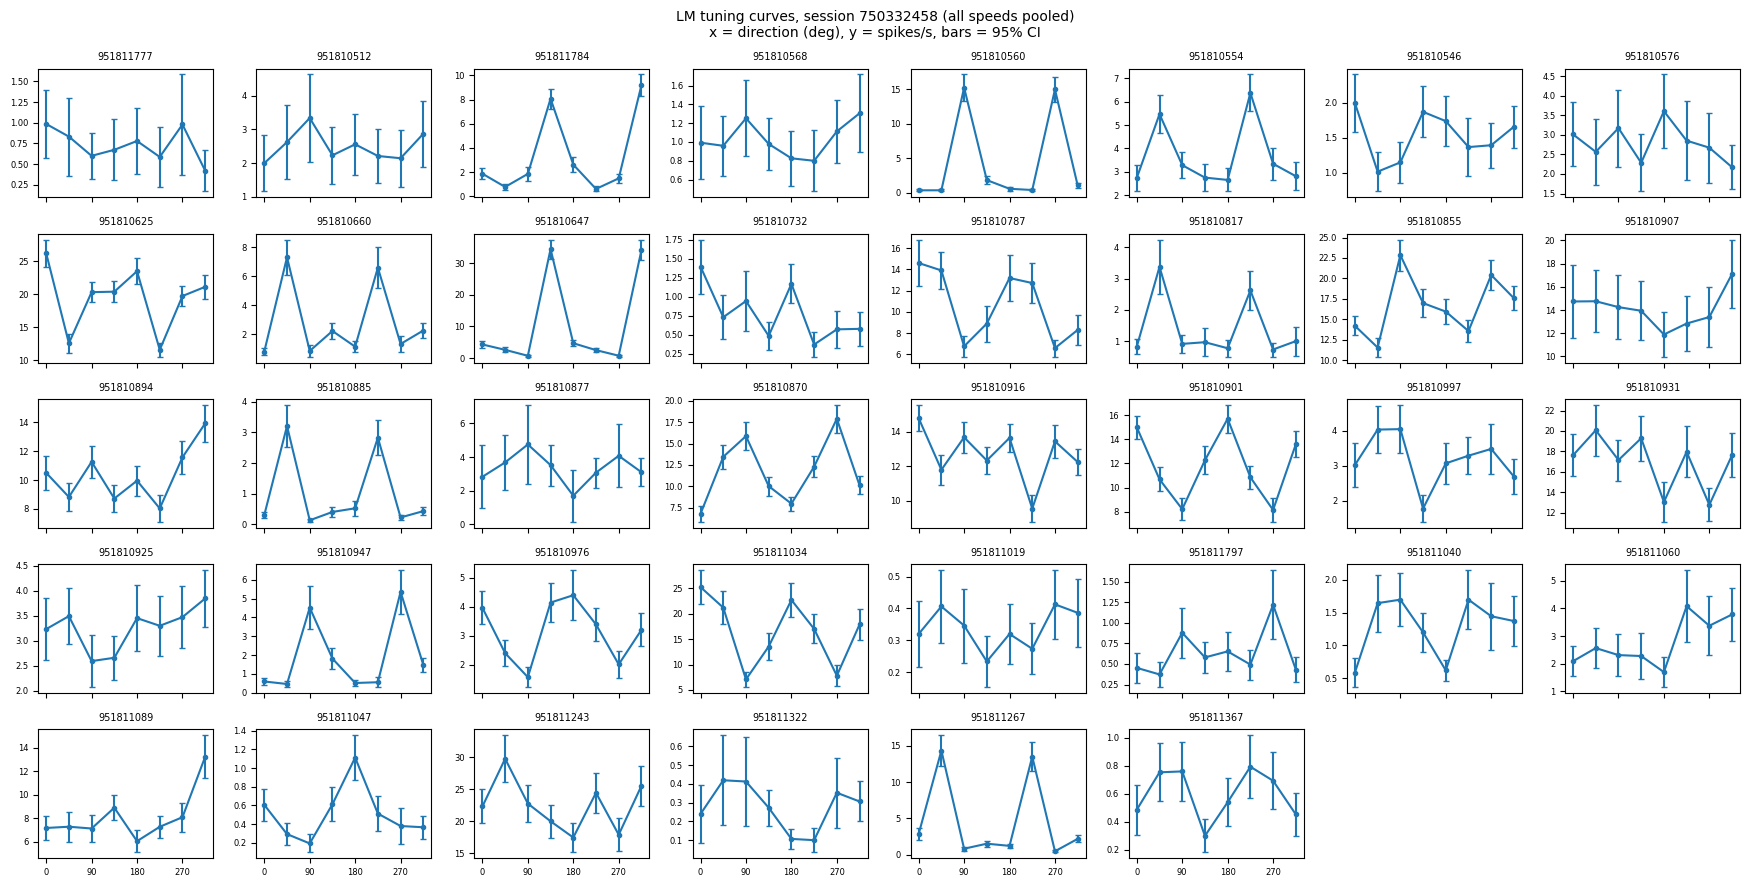

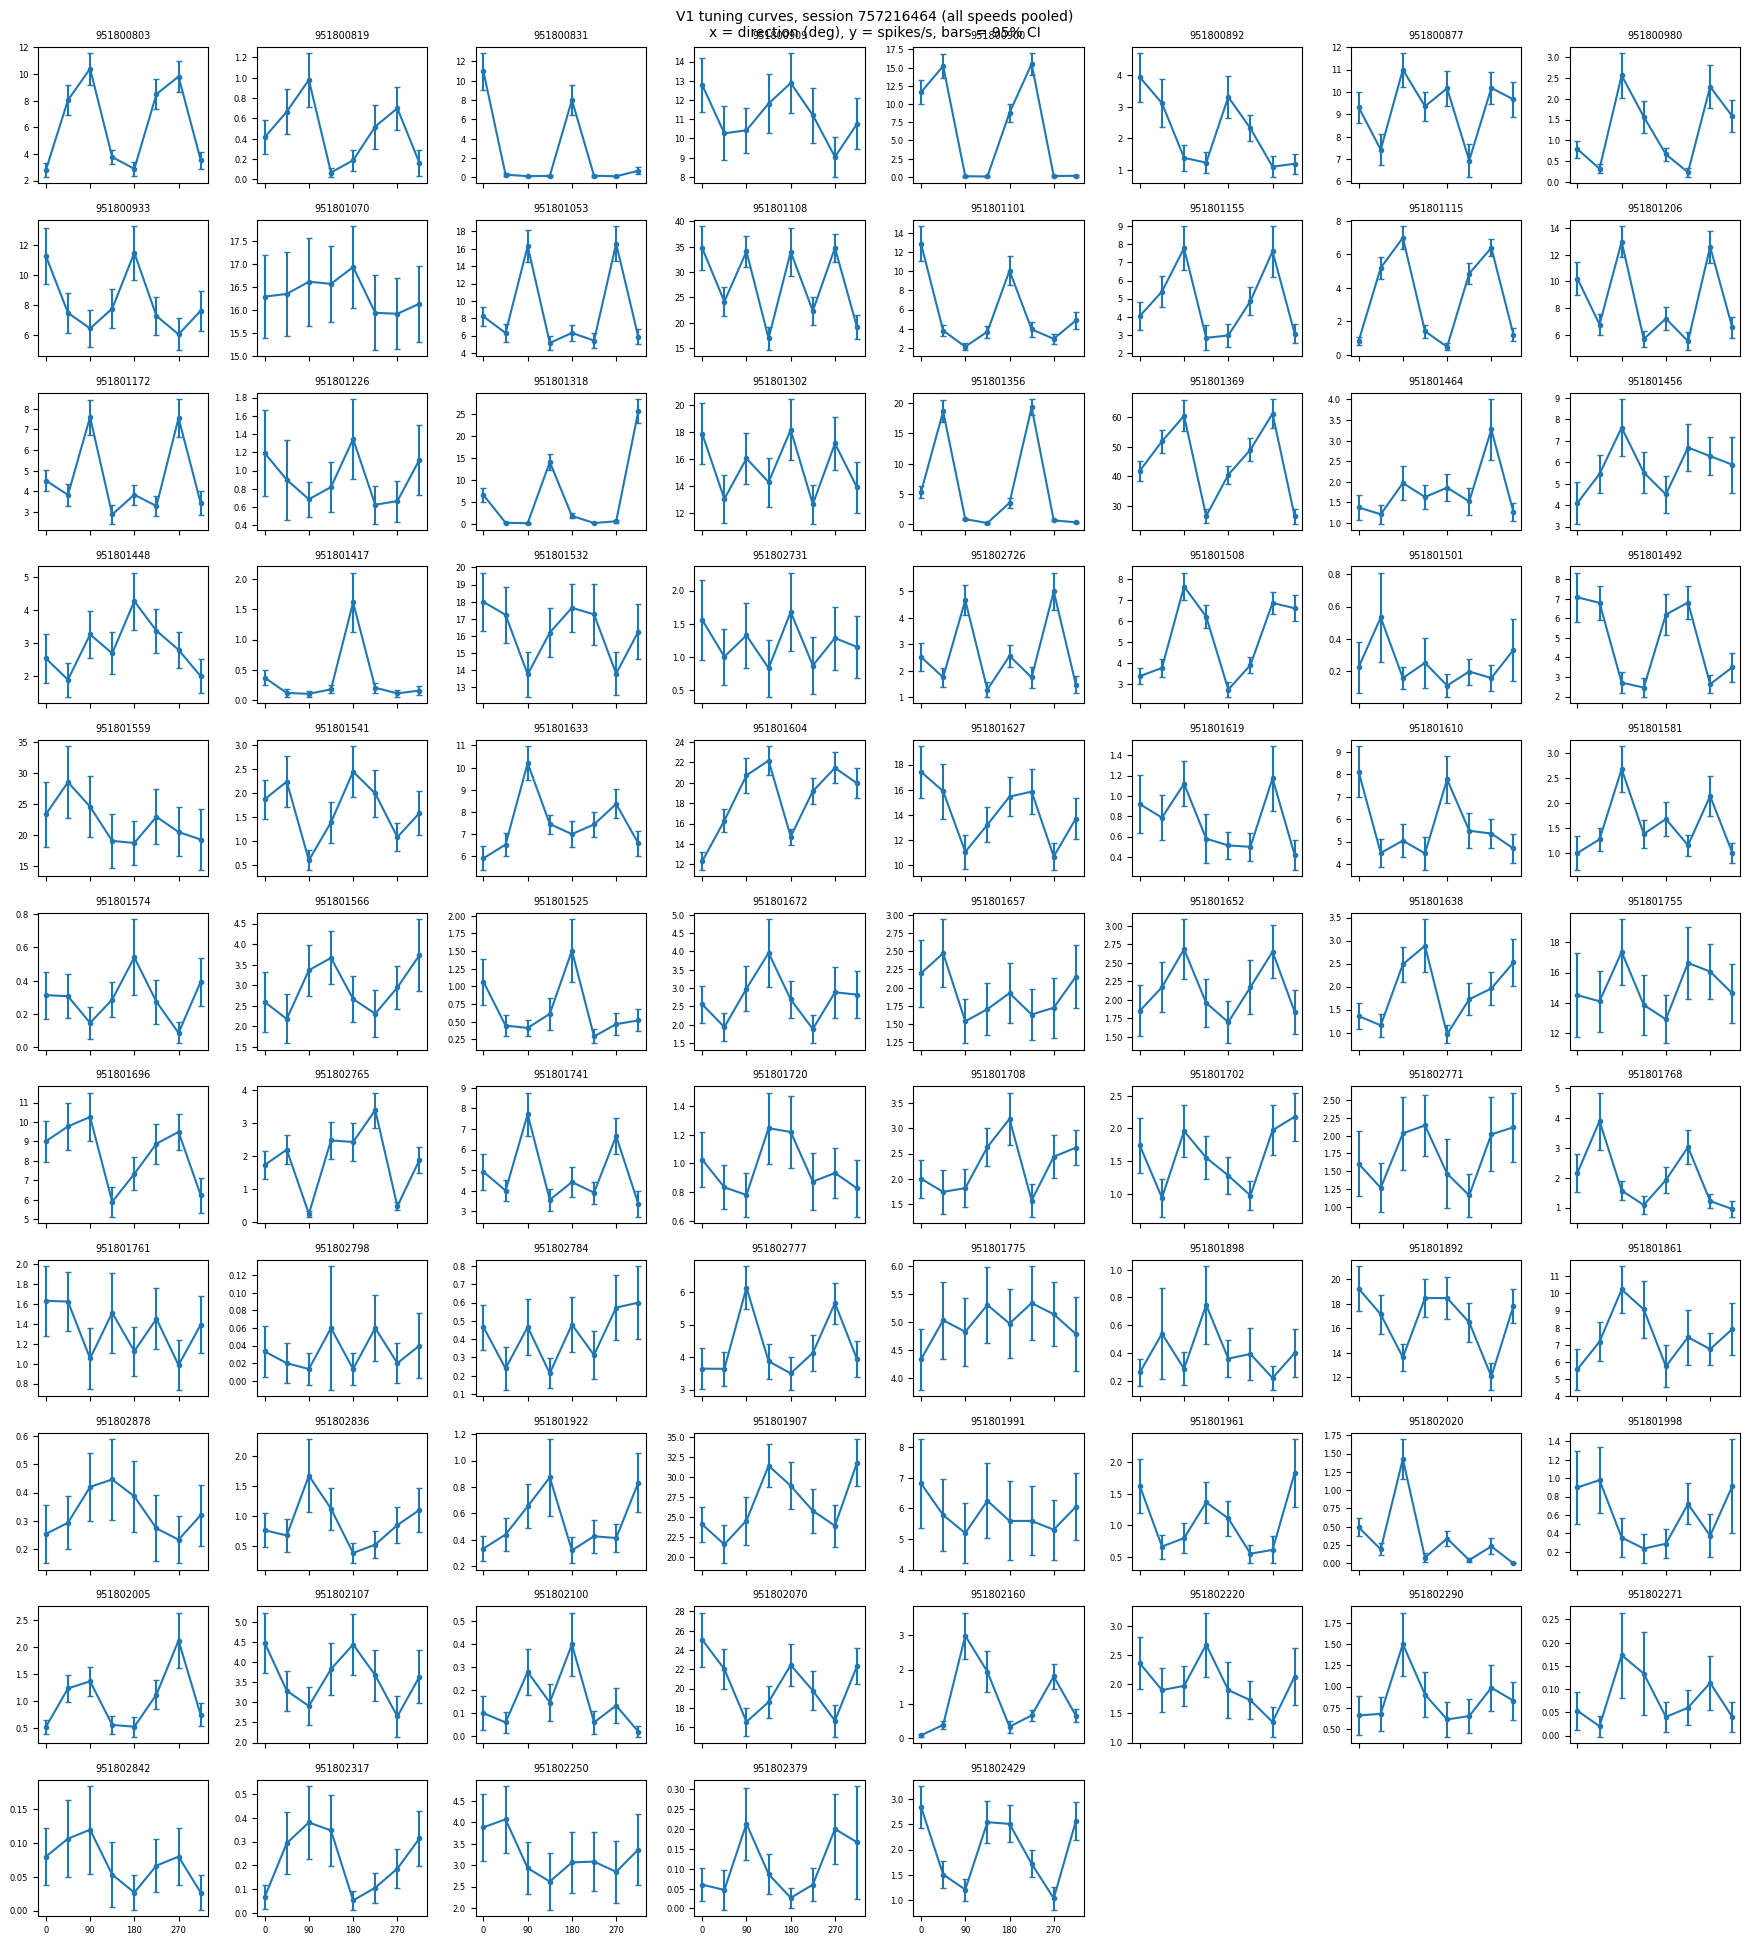

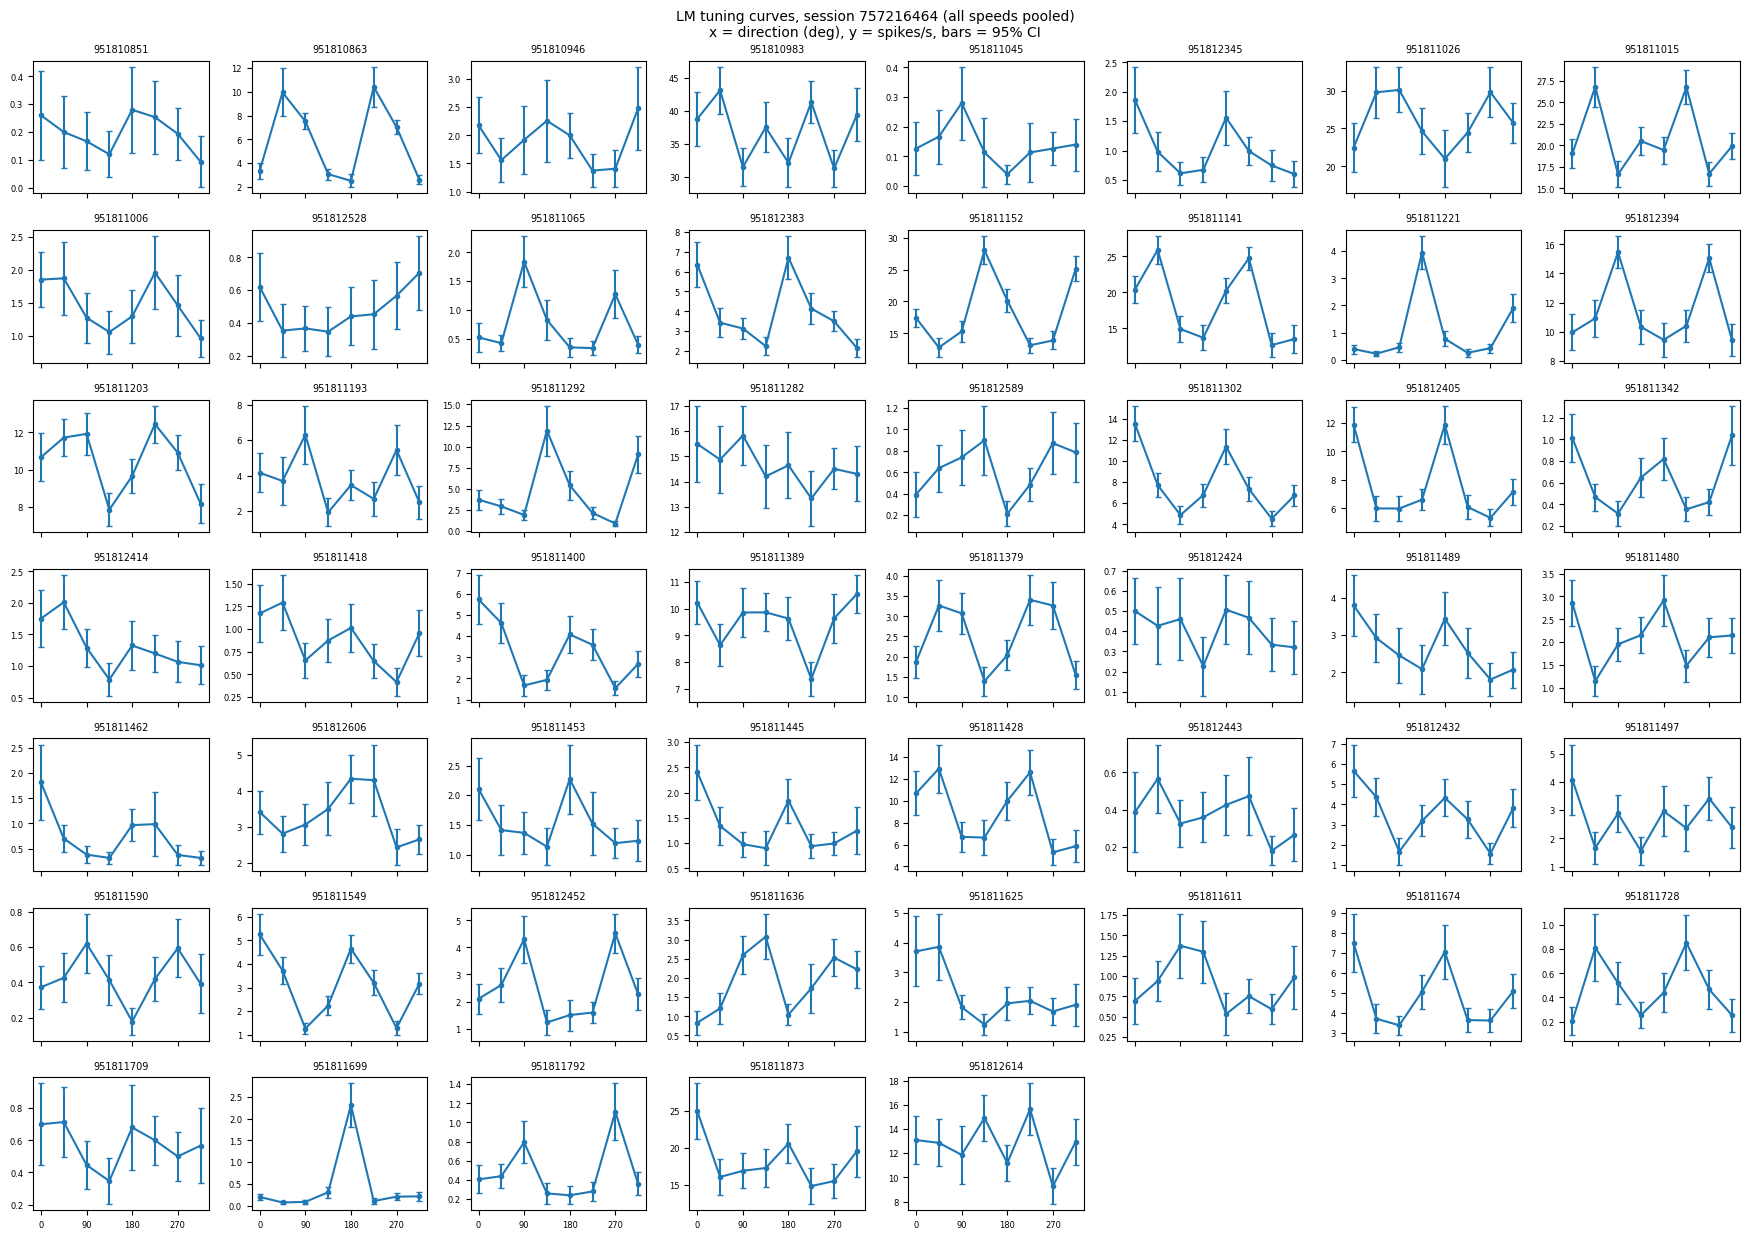

In [4]:
def plot_tuning_grid(sid, area, ncols=8):
    stim, units, counts, rates = data[sid]
    ids = units.index[units["ecephys_structure_acronym"] == area]
    nrows = int(np.ceil(len(ids) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.2 * ncols, 1.8 * nrows),
                             sharex=True, squeeze=False)
    for ax, uid in zip(axes.flat, ids):
        mean, ci = tuning_curve(rates[uid], stim)
        ax.errorbar(mean.index, mean.values, yerr=ci.values, fmt="o-", ms=3, capsize=2)
        ax.set_title(str(uid), fontsize=7)
        ax.set_xticks([0, 90, 180, 270])
        ax.tick_params(labelsize=6)
    for ax in axes.flat[len(ids):]:
        ax.axis("off")
    speed = "all speeds pooled" if TF is None else f"{TF:g} Hz"
    fig.suptitle(f"{AREA_NAMES[area]} tuning curves, session {sid} ({speed})\n"
                 "x = direction (deg), y = spikes/s, bars = 95% CI", fontsize=10)
    fig.tight_layout()
    fig.savefig(os.path.join(fig_dir, f"tuning_{AREA_NAMES[area]}_{sid}.png"), dpi=150)
    plt.show()

for sid in session_ids:
    for area in [V1, HOA]:
        plot_tuning_grid(sid, area)

## Analysis 2: correlation heatmaps

Each unit becomes a list of spike counts, one per trial. For every pair of units we compute the
Pearson correlation of those lists, giving an **N × N matrix**. Plotted as an image, it's symmetric,
with 1s on the diagonal (each unit with itself).

Units are ordered **V1 first, then LM** (black lines mark the boundary), and within each area
by preferred direction (the direction with the highest average firing rate). So the top-left block is V1–V1, bottom-right is LM–LM, and the
off-diagonal blocks are V1–LM.

The color scale is set from the off-diagonal values so small correlations are visible;
the diagonal (always 1) just shows as the darkest red.

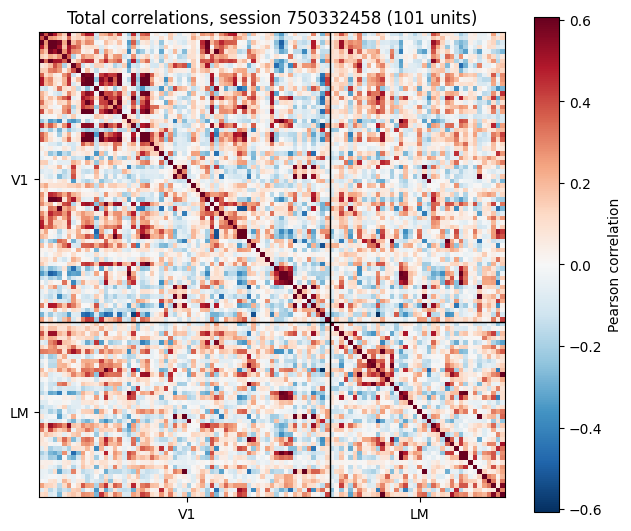

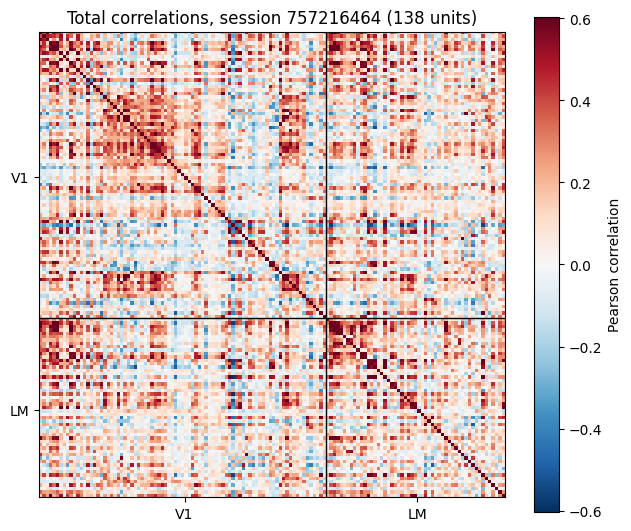

In [6]:
def unit_order(sid):
    stim, units, counts, rates = data[sid]
    # preferred direction = direction with the highest average firing rate
    pref = rates.groupby(stim["orientation"]).mean().idxmax()
    order = []
    for area in [V1, HOA]:
        ids = [u for u in units.index[units["ecephys_structure_acronym"] == area]
               if counts[u].std() > 0]  # skip units that never fired
        order += sorted(ids, key=lambda u: pref[u])
    n_v1 = int((units.loc[order, "ecephys_structure_acronym"] == V1).sum())
    return order, n_v1

def correlation_matrix(sid, kind="total"):
    stim, units, counts, rates = data[sid]
    order, n_v1 = unit_order(sid)
    X = counts[order].astype(float)
    if kind == "noise":
        # remove each condition's average response, keep only trial-to-trial fluctuations
        X = X - X.groupby([stim["orientation"], stim["temporal_frequency"]]).transform("mean")
    return np.corrcoef(X.values.T), n_v1

def plot_corr(sid, kind="total"):
    Cm, n_v1 = correlation_matrix(sid, kind)
    n = len(Cm)
    off = Cm[~np.eye(n, dtype=bool)]
    lim = np.nanpercentile(np.abs(off), 99)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    im = ax.imshow(Cm, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.axhline(n_v1 - 0.5, color="k", lw=1)
    ax.axvline(n_v1 - 0.5, color="k", lw=1)
    ticks = [n_v1 / 2, n_v1 + (n - n_v1) / 2]
    ax.set_xticks(ticks); ax.set_xticklabels(["V1", "LM"])
    ax.set_yticks(ticks); ax.set_yticklabels(["V1", "LM"])
    fig.colorbar(im, ax=ax, label="Pearson correlation")
    ax.set_title(f"{kind.capitalize()} correlations, session {sid} ({n} units)")
    fig.tight_layout()
    fig.savefig(os.path.join(fig_dir, f"corr_{kind}_{sid}.png"), dpi=150)
    plt.show()
    return Cm, n_v1

def block_means(Cm, n_v1):
    off = ~np.eye(len(Cm), dtype=bool)
    return {
        "V1-V1": np.nanmean(Cm[:n_v1, :n_v1][off[:n_v1, :n_v1]]),
        "LM-LM": np.nanmean(Cm[n_v1:, n_v1:][off[n_v1:, n_v1:]]),
        "V1-LM": np.nanmean(Cm[:n_v1, n_v1:]),
    }

block_rows = []
for sid in session_ids:
    Cm, n_v1 = plot_corr(sid, "total")
    block_rows.append({"session": sid, "kind": "total", **block_means(Cm, n_v1)})

### Optional: noise correlations

The correlations above ("total") mix two things:
- **Signal correlation**: two units both prefer the same directions, so they go up and down together across conditions
- **Noise correlation**: on repeats of the *same* grating, do they still fluctuate together from trial to trial?

Subtracting each condition's average response leaves only the trial-to-trial fluctuations.
Noise correlations are usually much smaller, and they're a common hint that units share inputs or are connected.

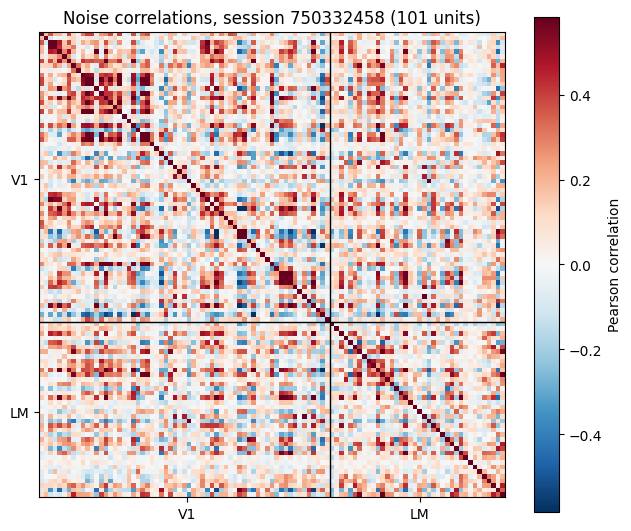

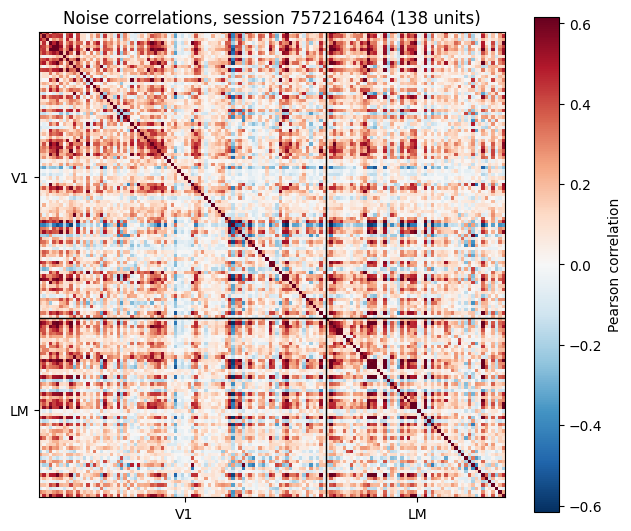

,,V1-V1,LM-LM,V1-LM
session,kind,,,
750332458,total,0.058,0.053,0.044
757216464,total,0.089,0.101,0.083
750332458,noise,0.070,0.063,0.055
757216464,noise,0.110,0.116,0.104


In [7]:
for sid in session_ids:
    Cm, n_v1 = plot_corr(sid, "noise")
    block_rows.append({"session": sid, "kind": "noise", **block_means(Cm, n_v1)})

# Average correlation in each block: within V1, within LM, and between V1 and LM
pd.DataFrame(block_rows).set_index(["session", "kind"]).round(3)

## Things to compare for your slides
- **Tuning curves**: do units in each area have clear peaks, or mostly flat curves?
- **Confidence intervals**: are responses more reliable (tighter error bars) in one area?
- **Firing rates**: does one area fire more overall?
- **Correlation blocks**: is V1–V1 stronger than LM–LM? How strong is V1–LM?
- **Two sessions**: do the same patterns show up in both mice?